# NextFlick: A Linear Algebra Approach to Movie Recommendations

## 1. Introduction

NextFlick is a movie recommendation project that uses linear algebra to analyse user preferences and identify movies that users may enjoy.

The project uses the MovieLens dataset, which contains movie information and user ratings. User preferences are represented as vectors, allowing mathematical techniques such as vector norms, dot products, cosine similarity and angles to be used to measure similarity between users.

The project demonstrates how linear algebra can be applied to a practical recommendation problem and evaluates the quality of its predictions.

### Objectives
- Represent user preferences using vectors and matrices.
- Apply vector norms, dot products and cosine similarity to compare users.
- Generate personalised movie recommendations.
- Demonstrate relevant linear algebra techniques on suitable matrices.
- Evaluate recommendation performance using prediction error metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

print("Number of movies:", len(movies))
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["userId"].nunique())

display(movies.head())
display(ratings.head())

Number of movies: 9742
Number of ratings: 100836
Number of users: 610


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Movies dataset shape: (9742, 3)
Ratings dataset shape: (100836, 4)

Missing values in movies:


movieId    0
title      0
genres     0
dtype: int64


Missing values in ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


Rating distribution:


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

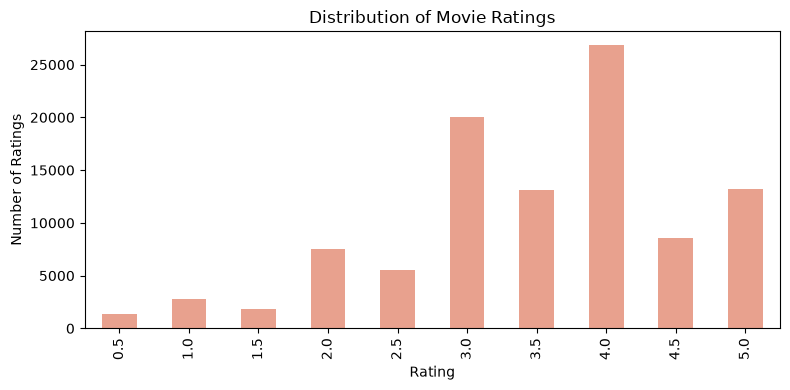

In [2]:
print("Movies dataset shape:", movies.shape)
print("Ratings dataset shape:", ratings.shape)

print("\nMissing values in movies:")
display(movies.isnull().sum())

print("\nMissing values in ratings:")
display(ratings.isnull().sum())

print("\nRating distribution:")
display(ratings["rating"].value_counts().sort_index())

ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4),
    title="Distribution of Movie Ratings",
    xlabel="Rating",
    ylabel="Number of Ratings",
    color="#E8A18E"
)

plt.tight_layout()
plt.show()

## 2. Representing Movie Ratings as a Matrix

A user–movie rating matrix represents the relationship between users and movies. Each row corresponds to a user, each column corresponds to a movie, and each entry represents the rating given by that user to that movie.

Since most users rate only a small fraction of all available movies, the matrix contains many missing entries. We preserve these missing values as NaN rather than treating them as zero, because a missing rating does not mean that a user disliked a movie.

In [3]:
rating_matrix = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Rating matrix dimensions:", rating_matrix.shape)

display(rating_matrix.iloc[:5, :10])

print("Total missing entries:", rating_matrix.isna().sum().sum())

print("Matrix sparsity:",
      round(rating_matrix.isna().sum().sum() /
            rating_matrix.size * 100, 2), "%")

Rating matrix dimensions: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Total missing entries: 5830804
Matrix sparsity: 98.3 %


## 3. User Similarity Using Vectors

Each user's ratings can be represented as a vector. To compare two users fairly, we consider only movies that both users have rated.

We subtract each user's mean rating on those shared movies to obtain centred rating vectors. This helps compare their relative preferences rather than simply whether they tend to give high or low ratings.

The following calculations demonstrate vector norms, dot products, cosine similarity and the angle between two users' preference vectors.

In [4]:
user_rating_data = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

user_1 = None
user_2 = None
shared_movies = None

for i in user_rating_data.index:
    for j in user_rating_data.index:
        if i >= j:
            continue

        common = user_rating_data.loc[[i, j]].dropna(axis=1)

        if common.shape[1] >= 10:
            v1 = common.loc[i].to_numpy(dtype=float)
            v2 = common.loc[j].to_numpy(dtype=float)

            if np.std(v1) > 0 and np.std(v2) > 0:
                user_1 = i
                user_2 = j
                shared_movies = common.columns
                break

    if user_1 is not None:
        break

print("User 1:", user_1)
print("User 2:", user_2)
print("Number of shared movies:", len(shared_movies))

User 1: 1
User 2: 4
Number of shared movies: 45


In [5]:
vector_1 = user_rating_data.loc[user_1, shared_movies].to_numpy(dtype=float)
vector_2 = user_rating_data.loc[user_2, shared_movies].to_numpy(dtype=float)

centred_1 = vector_1 - vector_1.mean()
centred_2 = vector_2 - vector_2.mean()

norm_1 = np.linalg.norm(centred_1)
norm_2 = np.linalg.norm(centred_2)

dot = np.dot(centred_1, centred_2)

cosine = dot / (norm_1 * norm_2)
cosine = np.clip(cosine, -1, 1)

angle = np.degrees(np.arccos(cosine))

print("User 1 vector norm:", round(norm_1, 4))
print("User 2 vector norm:", round(norm_2, 4))
print("Dot product:", round(dot, 4))
print("Cosine similarity:", round(cosine, 4))
print("Angle between vectors:", round(angle, 2), "degrees")

User 1 vector norm: 5.9142
User 2 vector norm: 9.0872
Dot product: 11.1778
Cosine similarity: 0.208
Angle between vectors: 78.0 degrees


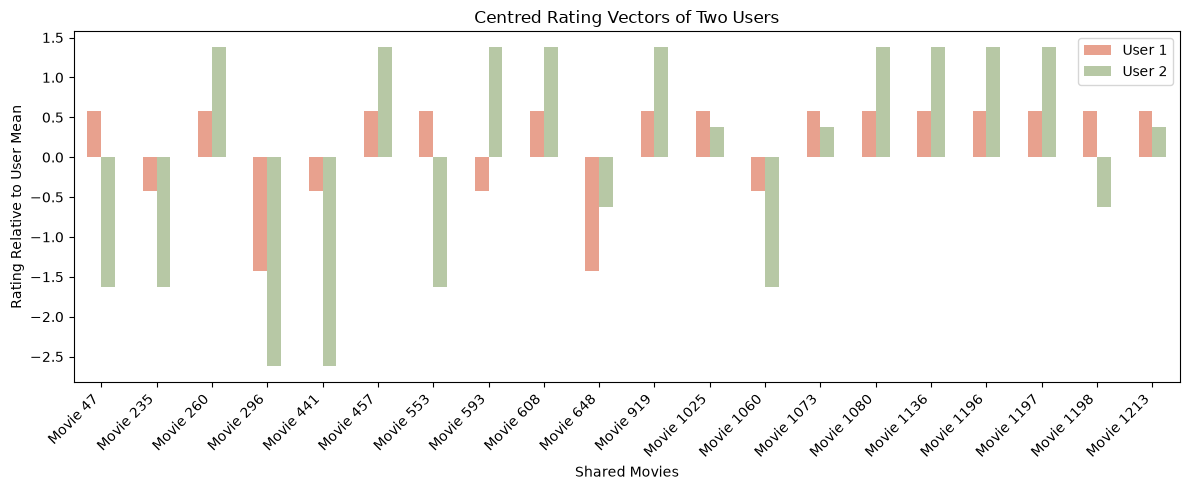

In [6]:
if len(shared_movies) > 0:
    comparison = pd.DataFrame({
        "User 1": centred_1,
        "User 2": centred_2
    })

    comparison.index = [f"Movie {movie_id}" for movie_id in shared_movies]

    comparison.head(20).plot(
        kind="bar",
        figsize=(12, 5),
        color=["#E8A18E", "#B7C8A5"]
    )

    plt.title("Centred Rating Vectors of Two Users")
    plt.xlabel("Shared Movies")
    plt.ylabel("Rating Relative to User Mean")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 4. Mathematical Interpretation of User Similarity

The dot product and vector norms are used to calculate cosine similarity.

Cosine Similarity = (u · v) / (||u|| × ||v||)

Here, u and v are the centred rating vectors of two users, and the angle between them is represented by theta.

A cosine similarity close to 1 indicates similar rating patterns. A value close to 0 indicates little linear alignment, while a value close to -1 indicates opposing rating patterns. These interpretations apply to the centred vectors used in this analysis.

Geometrically, a smaller angle between the vectors indicates greater alignment and therefore greater similarity between the users' rating patterns.

In [7]:
print(f"Cosine similarity: {cosine:.4f}")
print(f"Angle between vectors: {angle:.2f} degrees")

if cosine > 0.5:
    print("Interpretation: The users have positively aligned rating patterns.")
elif cosine < -0.5:
    print("Interpretation: The users have opposing rating patterns.")
else:
    print("Interpretation: The users have weak or moderate alignment.")

Cosine similarity: 0.2080
Angle between vectors: 78.00 degrees
Interpretation: The users have weak or moderate alignment.


## 5. Finding Similar Users

Comparing one pair of users demonstrates the mathematics, but a recommendation system must compare a target user against multiple other users.

For this analysis, we calculate cosine similarity between centred rating vectors using only the movies rated by both users. We require a minimum number of shared movies to reduce the influence of comparisons based on very little information.

In [8]:
def compare_users_in_notebook(user_a, user_b, min_shared=10):
    shared = user_rating_data.loc[[user_a, user_b]].dropna(axis=1)

    if shared.shape[1] < min_shared:
        return None

    a = shared.loc[user_a].to_numpy(dtype=float)
    b = shared.loc[user_b].to_numpy(dtype=float)

    a = a - a.mean()
    b = b - b.mean()

    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)

    if norm_a == 0 or norm_b == 0:
        return None

    similarity = np.dot(a, b) / (norm_a * norm_b)

    return float(np.clip(similarity, -1, 1))


target_user = user_1
similarities = []

for other_user in user_rating_data.index:
    if other_user == target_user:
        continue

    similarity = compare_users_in_notebook(target_user, other_user)

    if similarity is not None:
        similarities.append((other_user, similarity))

similar_users = pd.DataFrame(
    similarities,
    columns=["User ID", "Cosine Similarity"]
).sort_values("Cosine Similarity", ascending=False)

display(similar_users.head(10))

,User ID,Cosine Similarity
325,476,0.786936
143,210,0.767649
201,297,0.706281
31,44,0.684448
270,394,0.650600
172,248,0.624695
251,369,0.612098
51,72,0.596432
234,344,0.587609
79,112,0.583892


## 6. Movie Recommendation Using Similar Users

Users with similar rating patterns can help predict how a target user might rate movies they have not rated yet.

For each candidate movie, we calculate a weighted average of the ratings given by similar users. The cosine similarity values act as weights, so users with more similar preferences contribute more to the prediction.

The predicted ratings are then used to rank candidate movies and recommend the highest-scoring ones.

In [9]:
def recommend_movies_notebook(target_user, top_n=10, min_similarity=0.0):
    target_ratings = user_rating_data.loc[target_user].dropna()
    candidate_movies = user_rating_data.columns[
        ~user_rating_data.columns.isin(target_ratings.index)
    ]

    user_mean = target_ratings.mean()
    predictions = []

    for movie_id in candidate_movies:
        ratings_for_movie = user_rating_data[movie_id].dropna()

        common_users = ratings_for_movie.index.intersection(
            similar_users["User ID"]
        )

        if len(common_users) == 0:
            continue

        scores = similar_users.set_index("User ID")[
            "Cosine Similarity"
        ].reindex(common_users)

        valid = scores > min_similarity
        common_users = common_users[valid]
        scores = scores[valid]

        if len(common_users) == 0 or scores.sum() == 0:
            continue

        movie_ratings = user_rating_data.loc[
            common_users, movie_id
        ]

        predicted_rating = np.average(
            movie_ratings.to_numpy(dtype=float),
            weights=scores.to_numpy(dtype=float)
        )

        predictions.append((movie_id, predicted_rating))

    recommendations = pd.DataFrame(
        predictions,
        columns=["movieId", "Predicted Rating"]
    )

    recommendations = recommendations.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return recommendations.sort_values(
        "Predicted Rating", ascending=False
    ).head(top_n).reset_index(drop=True)


recommendations = recommend_movies_notebook(target_user, top_n=10)

display(recommendations)

,movieId,Predicted Rating,title,genres
0,112512,5.0,Colourful (Karafuru) (2010),Animation|Drama|Fantasy|Mystery
1,1105,5.0,Children of the Corn IV: The Gathering (1996),Horror
2,484,5.0,Lassie (1994),Adventure|Children
3,271,5.0,Losing Isaiah (1995),Drama
4,27373,5.0,61* (2001),Drama
5,175293,5.0,Gena the Crocodile (1969),Animation|Children
6,175397,5.0,"In the blue sea, in the white foam. (1984)",Animation|Children|Fantasy
7,175387,5.0,On the Trail of the Bremen Town Musicians (1973),Adventure|Animation|Children
8,549,5.0,Thirty-Two Short Films About Glenn Gould (1993),Drama|Musical
9,5416,5.0,Cherish (2002),Comedy|Drama|Thriller


### Interpretation

The recommendation table ranks movies that the target user has not rated, based on ratings from similar users. The predicted rating is an estimate, not an actual rating.

This approach illustrates how vector similarity can be translated into a practical recommendation system. Its effectiveness depends on the number of shared ratings, the quality of the similarity estimates and the availability of ratings for candidate movies.

## 7. Evaluation of the Recommendation Model

A recommendation model should be evaluated using ratings that were not used to make its predictions.

We use two common error metrics:

- **Mean Absolute Error (MAE):** the average absolute difference between predicted and actual ratings.
- **Root Mean Squared Error (RMSE):** the square root of the average squared prediction error, which penalises larger errors more strongly.

Lower values indicate more accurate predictions. We compare the recommendation model against a baseline that predicts the mean rating from the training data.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

train_matrix = train_ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

user_means = train_matrix.mean(axis=1)
global_mean = train_ratings["rating"].mean()

centred_matrix = train_matrix.sub(user_means, axis=0).fillna(0)

similarity_matrix = cosine_similarity(centred_matrix)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=train_matrix.index,
    columns=train_matrix.index
)

actual_ratings = []
test_predictions = []
baseline_predictions = []

for row in test_ratings.itertuples(index=False):
    user_id = row.userId
    movie_id = row.movieId
    actual = row.rating

    if user_id not in train_matrix.index:
        continue

    if movie_id not in train_matrix.columns:
        continue

    baseline = user_means.get(user_id, global_mean)

    similarities = similarity_df.loc[user_id].drop(user_id)

    movie_ratings = train_matrix[movie_id].dropna()
    neighbours = similarities.reindex(movie_ratings.index)

    valid = neighbours[neighbours > 0].sort_values(
        ascending=False
    ).head(20)

    if len(valid) > 0 and valid.sum() > 0:
        neighbour_ratings = movie_ratings.loc[valid.index]

        prediction = np.average(
            neighbour_ratings.to_numpy(dtype=float),
            weights=valid.to_numpy(dtype=float)
        )
    else:
        prediction = baseline

    prediction = np.clip(prediction, 0.5, 5.0)

    actual_ratings.append(actual)
    test_predictions.append(prediction)
    baseline_predictions.append(baseline)

actual_ratings = np.array(actual_ratings)
test_predictions = np.array(test_predictions)
baseline_predictions = np.array(baseline_predictions)

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "NextFlick": [
        mean_absolute_error(actual_ratings, test_predictions),
        np.sqrt(mean_squared_error(actual_ratings, test_predictions))
    ],
    "Baseline": [
        mean_absolute_error(actual_ratings, baseline_predictions),
        np.sqrt(mean_squared_error(actual_ratings, baseline_predictions))
    ]
})

display(results.round(4))

print("Test ratings evaluated:", len(actual_ratings))
print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))

,Metric,NextFlick,Baseline
0,MAE,0.7443,0.7389
1,RMSE,0.9640,0.9487


Test ratings evaluated: 19355
Training ratings: 80668
Testing ratings: 20168


### Interpretation of Evaluation Results

MAE measures the typical absolute prediction error, while RMSE gives greater weight to larger errors.

The baseline provides a reference point for assessing whether collaborative filtering improves prediction accuracy. If NextFlick achieves lower errors than the baseline, this provides evidence that user similarity is useful for predicting ratings. If it does not, the model may need improvement.

The metrics should be interpreted alongside the number of test ratings evaluated and the limitations of the dataset.

## 8. Row Reduced Echelon Form (RREF)

Row Reduced Echelon Form simplifies a matrix using elementary row operations. It helps identify pivot columns, determine the rank of a matrix and understand relationships between linear equations.

In this section, we apply RREF to a small example matrix to demonstrate the procedure clearly.

In [11]:
from sympy import Matrix

A = Matrix([
    [1, 2, 3],
    [2, 4, 6],
    [1, 1, 1]
])

print("Original matrix:")
display(A)

rref_matrix, pivot_columns = A.rref()

print("RREF:")
display(rref_matrix)

print("Pivot columns:", pivot_columns)
print("Rank:", A.rank())

Original matrix:


Matrix([
[1, 2, 3],
[2, 4, 6],
[1, 1, 1]])

RREF:


Matrix([
[1, 0, -1],
[0, 1,  2],
[0, 0,  0]])

Pivot columns: (0, 1)
Rank: 2


## 9. Basis of a Vector Space

A basis is a set of linearly independent vectors that spans a vector space. The number of vectors in a basis equals the dimension of that space.

In this example, we use the columns of a matrix to identify a basis for its column space using the pivot columns obtained from its reduced row echelon form.

In [12]:
A = Matrix([
    [1, 2, 3],
    [2, 4, 6],
    [1, 1, 1]
])

rref_matrix, pivot_columns = A.rref()

basis_vectors = A[:, list(pivot_columns)]

print("Original matrix:")
display(A)

print("RREF:")
display(rref_matrix)

print("Pivot columns:", pivot_columns)

print("Basis for the column space:")
display(basis_vectors)

print("Dimension of the column space:", len(pivot_columns))

Original matrix:


Matrix([
[1, 2, 3],
[2, 4, 6],
[1, 1, 1]])

RREF:


Matrix([
[1, 0, -1],
[0, 1,  2],
[0, 0,  0]])

Pivot columns: (0, 1)
Basis for the column space:


Matrix([
[1, 2],
[2, 4],
[1, 1]])

Dimension of the column space: 2


## 10. Gram–Schmidt Orthogonalisation

The Gram–Schmidt process converts a set of linearly independent vectors into an orthogonal set that spans the same subspace.

For two vectors, the second orthogonal vector is obtained by subtracting the projection of the second vector onto the first.

u₂ = v₂ − [(v₂ · u₁) / (u₁ · u₁)] u₁

The resulting vectors are orthogonal if their dot product is zero.

In [13]:
v1 = np.array([1.0, 1.0, 0.0])
v2 = np.array([1.0, 0.0, 1.0])

u1 = v1.copy()
u2 = v2 - (np.dot(v2, u1) / np.dot(u1, u1)) * u1

print("First orthogonal vector:")
print(u1)

print("Second orthogonal vector:")
print(u2)

print("Dot product of orthogonal vectors:", np.dot(u1, u2))

e1 = u1 / np.linalg.norm(u1)
e2 = u2 / np.linalg.norm(u2)

print("First orthonormal vector:")
print(e1)

print("Second orthonormal vector:")
print(e2)

print("Norms:", np.linalg.norm(e1), np.linalg.norm(e2))

First orthogonal vector:
[1. 1. 0.]
Second orthogonal vector:
[ 0.5 -0.5  1. ]
Dot product of orthogonal vectors: 0.0
First orthonormal vector:
[0.70710678 0.70710678 0.        ]
Second orthonormal vector:
[ 0.40824829 -0.40824829  0.81649658]
Norms: 0.9999999999999999 1.0


## 11. Vector Projection

Vector projection finds the component of one vector in the direction of another vector.

The projection of vector b onto a non-zero vector a is given by:

Projection of b onto a = [(b · a) / (a · a)] a

The difference between vector b and its projection is orthogonal to vector a. This is useful for understanding how vectors can be decomposed into parallel and perpendicular components.

In [14]:
a = np.array([1.0, 2.0, 0.0])
b = np.array([2.0, 1.0, 3.0])

projection = (np.dot(b, a) / np.dot(a, a)) * a
residual = b - projection

print("Vector a:", a)
print("Vector b:", b)
print("Projection of b onto a:", projection)
print("Residual:", residual)
print("Dot product of a and residual:", np.dot(a, residual))

Vector a: [1. 2. 0.]
Vector b: [2. 1. 3.]
Projection of b onto a: [0.8 1.6 0. ]
Residual: [ 1.2 -0.6  3. ]
Dot product of a and residual: -2.220446049250313e-16


## 12. Least-Squares Approximation

When a system of linear equations has no exact solution, the least-squares method finds an approximate solution that minimises the sum of squared residuals.

For a matrix A and observation vector b, the objective is:

Minimise ||Ax − b||²

When the columns of A are linearly independent, the solution satisfies the normal equations:

AᵀA x̂ = Aᵀb

The resulting residual is orthogonal to the column space of A.

In [15]:
A_ls = np.array([
    [1.0, 1.0],
    [1.0, 2.0],
    [1.0, 3.0],
    [1.0, 4.0]
])

b_ls = np.array([2.1, 2.9, 4.2, 4.8])

x_hat, residuals, rank, singular_values = np.linalg.lstsq(
    A_ls, b_ls, rcond=None
)

predicted = A_ls @ x_hat
residual_vector = b_ls - predicted

print("Least-squares coefficients:", x_hat)
print("Predicted values:", predicted)
print("Residual vector:", residual_vector)
print("Sum of squared residuals:", np.sum(residual_vector ** 2))
print("A^T times residual:", A_ls.T @ residual_vector)

Least-squares coefficients: [1.15 0.94]
Predicted values: [2.09 3.03 3.97 4.91]
Residual vector: [ 0.01 -0.13  0.23 -0.11]
Sum of squared residuals: 0.08199999999999993
A^T times residual: [1.77635684e-15 4.88498131e-15]


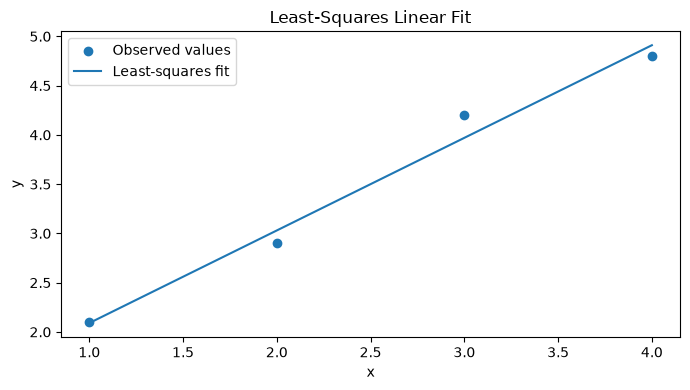

In [16]:
x_values = A_ls[:, 1]

plt.figure(figsize=(7, 4))
plt.scatter(x_values, b_ls, label="Observed values")
plt.plot(x_values, predicted, label="Least-squares fit")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Least-Squares Linear Fit")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Eigenvalues and Eigenvectors

For a square matrix A, an eigenvector is a non-zero vector whose direction remains unchanged when multiplied by A. The corresponding eigenvalue describes the scaling factor.

They satisfy the equation:

Av = λv

Here, v is the eigenvector and λ is the corresponding eigenvalue.

Eigenvalues and eigenvectors are useful in analysing matrix structure and identifying important directions in data. They also form the mathematical foundation of techniques such as Principal Component Analysis (PCA).

In [17]:
A_eigen = np.array([
    [4.0, 1.0],
    [1.0, 3.0]
])

eigenvalues, eigenvectors = np.linalg.eig(A_eigen)

print("Matrix A:")
display(pd.DataFrame(A_eigen))

print("Eigenvalues:")
print(eigenvalues)

print("Eigenvectors (columns):")
display(pd.DataFrame(eigenvectors))

for i, value in enumerate(eigenvalues):
    v = eigenvectors[:, i]
    print(
        f"Eigenvector {i + 1}:",
        v,
        "| Verification error:",
        np.linalg.norm(A_eigen @ v - value * v)
    )

Matrix A:


,0,1
0,4.0,1.0
1,1.0,3.0


Eigenvalues:
[4.61803399+0.j 2.38196601+0.j]
Eigenvectors (columns):


,0,1
0,0.850651+0.000000j,-0.525731+0.000000j
1,0.525731+0.000000j,0.850651+0.000000j


Eigenvector 1: [0.85065081+0.j 0.52573111+0.j] | Verification error: 0.0
Eigenvector 2: [-0.52573111+0.j  0.85065081+0.j] | Verification error: 2.220446049250313e-16


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/matplotlib/transforms.py:1913: ComplexWarning: Casting complex values to real discards the imaginary part
  return affine_transform(values, mtx)


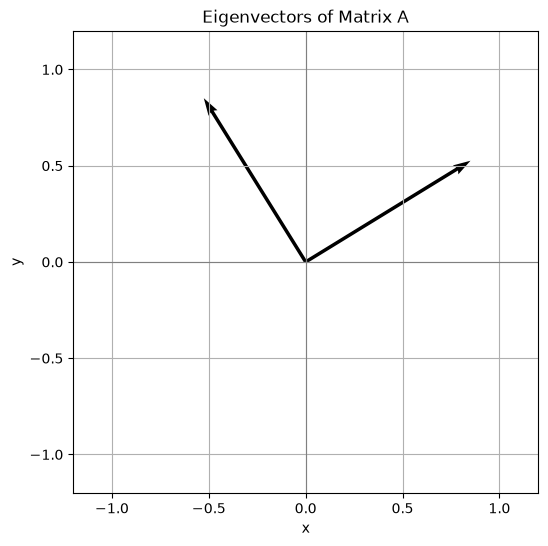

In [18]:
plt.figure(figsize=(6, 6))

origin = np.array([[0, 0], [0, 0]])

plt.quiver(
    origin[:, 0],
    origin[:, 1],
    eigenvectors[0, :],
    eigenvectors[1, :],
    angles="xy",
    scale_units="xy",
    scale=1
)

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Eigenvectors of Matrix A")
plt.show()

## 14. Application of Linear Algebra in NextFlick

NextFlick applies linear algebra to a movie recommendation problem by representing users' preferences as numerical vectors.

- **Matrices:** Organise user ratings across movies.
- **Vector norms:** Measure the magnitude of rating vectors.
- **Dot products:** Quantify alignment between vectors.
- **Cosine similarity and angles:** Compare the relative rating patterns of users.
- **Least squares and residuals:** Demonstrate how approximate solutions and prediction errors can be analysed.
- **RREF and basis:** Demonstrate linear independence, rank and subspace structure.
- **Gram–Schmidt orthogonalisation:** Constructs orthogonal vectors spanning the same subspace.
- **Eigenvalues and eigenvectors:** Explain matrix structure and provide a foundation for dimensionality-reduction methods.

The recommendation system uses user similarity to estimate ratings for movies a user has not rated. The other mathematical examples demonstrate complementary linear algebra techniques on smaller matrices.

## 15. Conclusion

This project demonstrates how linear algebra can be applied to a practical movie recommendation problem. By representing user preferences as vectors, NextFlick compares rating patterns using cosine similarity and uses these similarities to estimate preferences for unrated movies.

The notebook also demonstrates matrix reduction, basis construction, orthogonalisation, projection, least-squares approximation and eigenanalysis. Evaluation using MAE and RMSE provides a quantitative way to assess rating predictions against a baseline.

The project illustrates both the practical value of vector-based similarity and the broader role of linear algebra in data analysis and recommendation systems.

### Limitations

The recommendations depend on the availability of shared ratings and the quality of the similarity estimates. Users with few ratings may receive less reliable recommendations, and predicted ratings are estimates rather than guarantees of user preference.

In [19]:
import numpy as np
import pandas as pd

movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

user_rating_data = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Rating matrix:", user_rating_data.shape)

Rating matrix: (610, 9724)


In [20]:
import ipywidgets as widgets
from IPython.display import display, clear_output

rating_matrix = user_rating_data.copy()
user_means = rating_matrix.mean(axis=1)

user_dropdown = widgets.Dropdown(
    options=sorted(rating_matrix.index.tolist()),
    description="User ID:",
    layout=widgets.Layout(width="300px")
)

recommend_button = widgets.Button(
    description="Recommend Movies",
    button_style="success",
    icon="film"
)

output = widgets.Output()


def show_recommendations(button):
    with output:
        clear_output(wait=True)

        selected_user = user_dropdown.value
        target_ratings = rating_matrix.loc[selected_user].dropna()
        target_mean = target_ratings.mean()

        similarities = []

        for other_user in rating_matrix.index:
            if other_user == selected_user:
                continue

            common = rating_matrix.loc[
                [selected_user, other_user]
            ].dropna(axis=1)

            if len(common.columns) < 5:
                continue

            a = common.loc[selected_user].to_numpy(dtype=float)
            b = common.loc[other_user].to_numpy(dtype=float)

            a = a - a.mean()
            b = b - b.mean()

            denominator = np.linalg.norm(a) * np.linalg.norm(b)

            if denominator == 0:
                continue

            similarity = np.dot(a, b) / denominator

            if similarity > 0:
                similarities.append((other_user, similarity))

        similarities.sort(key=lambda item: item[1], reverse=True)
        top_users = similarities[:50]

        print(f"NextFlick Recommendations for User {selected_user}")
        print(f"Movies already rated: {len(target_ratings)}")

        print("\nMost similar users:")

        similar_table = pd.DataFrame(
            top_users[:5],
            columns=["Similar User ID", "Cosine Similarity"]
        )

        display(
            similar_table.style.format(
                {"Cosine Similarity": "{:.4f}"}
            )
        )

        predictions = []

        for movie_id in rating_matrix.columns:
            if movie_id in target_ratings.index:
                continue

            weighted_deviation = 0.0
            weight_sum = 0.0
            neighbour_count = 0

            for other_user, similarity in top_users:
                neighbour_rating = rating_matrix.loc[
                    other_user, movie_id
                ]

                if pd.isna(neighbour_rating):
                    continue

                neighbour_mean = user_means.loc[other_user]

                weighted_deviation += similarity * (
                    neighbour_rating - neighbour_mean
                )

                weight_sum += similarity
                neighbour_count += 1

            if weight_sum > 0 and neighbour_count >= 2:
                prediction = target_mean + (
                    weighted_deviation / weight_sum
                )

                prediction = float(np.clip(prediction, 0.5, 5.0))

                predictions.append((movie_id, prediction))

        if not predictions:
            print("\nNo recommendations could be generated.")
            return

        result = pd.DataFrame(
            predictions,
            columns=["movieId", "Predicted Rating"]
        )

        result = result.merge(
            movies[["movieId", "title", "genres"]],
            on="movieId",
            how="left"
        )

        result = result.dropna(subset=["title"])

        print("\nPrediction distribution:")
        print(
            result["Predicted Rating"]
            .describe()
            .round(4)
        )

        result = result.sort_values(
            "Predicted Rating",
            ascending=False
        ).head(10).reset_index(drop=True)

        result["Predicted Rating"] = result[
            "Predicted Rating"
        ].round(3)

        print("\nTop 10 recommended movies:")

        display(
            result[
                ["title", "genres", "Predicted Rating"]
            ]
        )


recommend_button.on_click(show_recommendations)

display(user_dropdown, recommend_button, output)

Dropdown(description='User ID:', layout=Layout(width='300px'), options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,…

Button(button_style='success', description='Recommend Movies', icon='film', style=ButtonStyle())

Output()

### Interpretation of Recommendation Results

NextFlick identifies users with similar rating patterns using cosine similarity. It then predicts ratings for movies the selected user has not rated, using a similarity-weighted average of ratings from similar users.

The movies are ranked by their predicted ratings, with higher scores indicating stronger predicted preferences. These predictions are estimates and do not guarantee that the user will like a movie.

The results demonstrate how vector similarity can be applied to a practical recommendation problem.